In [ ]:
import os
import contextlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score


# ==========================================
# 1. Auto-Detect MRNet Path & Build Splits
# ==========================================
def find_mrnet_root(base_dir="/kaggle/input"):
    for root, _, files in os.walk(base_dir):
        if "train-abnormal.csv" in files:
            print(f"[INFO] Found MRNet dataset at: {root}")
            return root
    raise FileNotFoundError(
        f"Could not locate 'train-abnormal.csv' inside {base_dir}. "
        "Verify that 'cjinny/mrnet-v1' is attached in the right-hand Input panel."
    )


def build_dataframes(root_dir):
    tasks = ["abnormal", "acl", "meniscus"]

    def load_split(prefix):
        dfs = []
        for t in tasks:
            path = os.path.join(root_dir, f"{prefix}-{t}.csv")
            df = pd.read_csv(path, header=None, names=["case", t], dtype={"case": str, t: int})
            df["case"] = df["case"].str.strip().str.zfill(4)
            dfs.append(df.set_index("case"))
        merged = pd.concat(dfs, axis=1).reset_index()
        merged["folder"] = prefix
        return merged

    full_train_df = load_split("train")
    test_df = load_split("valid")

    strat_key = full_train_df["abnormal"].astype(str) + "_" + full_train_df["acl"].astype(str)
    train_df, val_df = train_test_split(
        full_train_df, test_size=0.15, random_state=42, stratify=strat_key
    )
    return train_df, val_df, test_df


# ==========================================
# 2. Multi-Plane MRNet Dataset Loader
# ==========================================
class MRNetDataset(Dataset):
    def __init__(self, root_dir, split_df, max_slices=48):
        self.root_dir = root_dir
        self.df = split_df.reset_index(drop=True)
        self.max_slices = max_slices
        self.planes = ["sagittal", "coronal", "axial"]

    def __len__(self):
        return len(self.df)

    def _process_volume(self, vol):
        s = vol.shape[0]
        if s > self.max_slices:
            start = (s - self.max_slices) // 2
            vol = vol[start : start + self.max_slices]

        vol = vol.astype(np.float32) / 255.0
        vol = np.stack([vol] * 3, axis=1)  # (S, 3, 256, 256)

        mean = np.array([0.485, 0.456, 0.406], dtype=np.float32).reshape(1, 3, 1, 1)
        std = np.array([0.229, 0.224, 0.225], dtype=np.float32).reshape(1, 3, 1, 1)
        vol = (vol - mean) / std
        return torch.from_numpy(vol)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        case_id = str(row["case"]).zfill(4)
        folder = row["folder"]

        volumes = {}
        for plane in self.planes:
            npy_path = os.path.join(self.root_dir, folder, plane, f"{case_id}.npy")
            vol = np.load(npy_path)
            volumes[plane] = self._process_volume(vol)

        labels = torch.tensor(
            [row["abnormal"], row["acl"], row["meniscus"]], dtype=torch.float32
        )
        return volumes["sagittal"], volumes["coronal"], volumes["axial"], labels


# ==========================================
# 3. Gated Attention MIL & Cross-Attention
# ==========================================
class GatedAttentionMIL(nn.Module):
    def __init__(self, in_features, hidden_dim=256):
        super().__init__()
        self.V = nn.Linear(in_features, hidden_dim)
        self.U = nn.Linear(in_features, hidden_dim)
        self.w = nn.Linear(hidden_dim, 1)

    def forward(self, h):
        a_v = torch.tanh(self.V(h))
        a_u = torch.sigmoid(self.U(h))
        scores = self.w(a_v * a_u)
        weights = torch.softmax(scores, dim=0)
        bag_embedding = torch.sum(weights * h, dim=0, keepdim=True)
        return bag_embedding, weights.squeeze(-1)


class MultiPlaneCrossAttentionNet(nn.Module):
    def __init__(self, num_classes=3, embed_dim=768):
        super().__init__()
        try:
            backbone = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
            print("[INFO] Loaded ImageNet-pretrained ConvNeXt-Tiny weights.")
        except Exception as e:
            print(f"[WARNING] Pretrained weight download failed ({e}). "
                  "Enable 'Internet' in Kaggle Settings for best AUROC. Using random init.")
            backbone = models.convnext_tiny(weights=None)

        self.feature_extractor = backbone.features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))

        self.mil_sag = GatedAttentionMIL(embed_dim)
        self.mil_cor = GatedAttentionMIL(embed_dim)
        self.mil_axi = GatedAttentionMIL(embed_dim)

        self.plane_pos = nn.Parameter(torch.randn(1, 3, embed_dim) * 0.02)

        self.cross_attn = nn.MultiheadAttention(
            embed_dim=embed_dim, num_heads=8, dropout=0.2, batch_first=True
        )
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 2),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(embed_dim * 2, embed_dim),
        )
        self.classifier = nn.Linear(embed_dim * 3, num_classes)

    def _encode_slices(self, x):
        x = x.squeeze(0)  # (S, 3, 256, 256)
        return self.pool(self.feature_extractor(x)).flatten(1)  # (S, 768)

    def forward(self, sag, cor, axi):
        h_sag = self._encode_slices(sag)
        h_cor = self._encode_slices(cor)
        h_axi = self._encode_slices(axi)

        e_sag, w_sag = self.mil_sag(h_sag)
        e_cor, w_cor = self.mil_cor(h_cor)
        e_axi, w_axi = self.mil_axi(h_axi)

        tokens = torch.stack([e_sag, e_cor, e_axi], dim=1) + self.plane_pos
        attn_out, _ = self.cross_attn(tokens, tokens, tokens)
        tokens = self.norm1(tokens + attn_out)
        tokens = self.norm2(tokens + self.ffn(tokens))

        logits = self.classifier(tokens.flatten(1))
        return logits, (w_sag, w_cor, w_axi)


# ==========================================
# 4. Asymmetric Focal Loss (ASL)
# ==========================================
class AsymmetricLoss(nn.Module):
    def __init__(self, gamma_neg=4, gamma_pos=1, clip=0.05, eps=1e-8):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.eps = eps

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_pos = probs
        probs_neg = 1.0 - probs

        if self.clip is not None and self.clip > 0:
            probs_neg = (probs_neg + self.clip).clamp(max=1.0)

        los_pos = targets * torch.log(probs_pos.clamp(min=self.eps))
        los_neg = (1.0 - targets) * torch.log(probs_neg.clamp(min=self.eps))
        loss = los_pos + los_neg

        if self.gamma_neg > 0 or self.gamma_pos > 0:
            pt = probs_pos * targets + probs_neg * (1.0 - targets)
            one_sided_gamma = self.gamma_pos * targets + self.gamma_neg * (1.0 - targets)
            loss *= torch.pow(1.0 - pt, one_sided_gamma)

        return -loss.mean()


# ==========================================
# 5. Training & Evaluation Loop
# ==========================================
def evaluate(model, loader, device, use_cuda):
    model.eval()
    all_targets, all_probs = [], []
    amp_ctx = torch.amp.autocast("cuda") if use_cuda else contextlib.nullcontext()

    with torch.no_grad():
        for sag, cor, axi, labels in loader:
            sag, cor, axi = sag.to(device), cor.to(device), axi.to(device)
            with amp_ctx:
                logits, _ = model(sag, cor, axi)
                probs = torch.sigmoid(logits).cpu().numpy()
            all_probs.append(probs[0])
            all_targets.append(labels.numpy()[0])

    all_targets = np.array(all_targets)
    all_probs = np.array(all_probs)
    aucs = [roc_auc_score(all_targets[:, i], all_probs[:, i]) for i in range(3)]
    return aucs, float(np.mean(aucs))


def run_training(epochs=15, accum_steps=16):
    use_cuda = torch.cuda.is_available()
    device = torch.device("cuda" if use_cuda else "cpu")
    print(f"[INFO] Running on device: {device}")
    if not use_cuda:
        print("[WARNING] GPU is not enabled! Turn on GPU T4 x2 or P100 in Kaggle Session options.")

    root_dir = find_mrnet_root("/kaggle/input")
    train_df, val_df, test_df = build_dataframes(root_dir)
    print(f"[INFO] Split sizes -> Train: {len(train_df)}, Val: {len(val_df)}, Test: {len(test_df)}")

    train_loader = DataLoader(MRNetDataset(root_dir, train_df), batch_size=1, shuffle=True, num_workers=2)
    val_loader = DataLoader(MRNetDataset(root_dir, val_df), batch_size=1, shuffle=False, num_workers=2)
    test_loader = DataLoader(MRNetDataset(root_dir, test_df), batch_size=1, shuffle=False, num_workers=2)

    model = MultiPlaneCrossAttentionNet().to(device)
    criterion = AsymmetricLoss(gamma_neg=4, gamma_pos=1, clip=0.05)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)
    amp_ctx = torch.amp.autocast("cuda") if use_cuda else contextlib.nullcontext()

    best_auc = 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        running_loss = 0.0

        for step, (sag, cor, axi, labels) in enumerate(train_loader, 1):
            sag, cor, axi, labels = (
                sag.to(device),
                cor.to(device),
                axi.to(device),
                labels.to(device),
            )

            with amp_ctx:
                logits, _ = model(sag, cor, axi)
                loss = criterion(logits, labels) / accum_steps

            if use_cuda:
                scaler.scale(loss).backward()
            else:
                loss.backward()

            running_loss += loss.item() * accum_steps

            if step % accum_steps == 0 or step == len(train_loader):
                if use_cuda:
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    optimizer.step()
                optimizer.zero_grad()

            if step % 200 == 0:
                print(f"  Epoch {epoch:02d} | Step {step}/{len(train_loader)} | Avg Loss: {running_loss/step:.4f}")

        val_aucs, mean_val_auc = evaluate(model, val_loader, device, use_cuda)
        print(
            f"Epoch {epoch:02d} Summary | Loss: {running_loss/len(train_loader):.4f} | "
            f"Val AUC -> Abn: {val_aucs[0]:.4f}, ACL: {val_aucs[1]:.4f}, Men: {val_aucs[2]:.4f} | "
            f"Mean: {mean_val_auc:.4f}"
        )

        if mean_val_auc > best_auc:
            best_auc = mean_val_auc
            torch.save(model.state_dict(), "best_multiplane_mil.pth")
            print(f"  --> Saved new best checkpoint (Mean Val AUC: {best_auc:.4f})")

    # Final evaluation on the held-out 120-case MRNet validation/test cohort
    model.load_state_dict(torch.load("best_multiplane_mil.pth", map_location=device))
    test_aucs, mean_test_auc = evaluate(model, test_loader, device, use_cuda)
    print(
        f"\n[FINAL TEST RESULTS] Held-Out Cohort (n={len(test_df)}) | "
        f"Abnormal: {test_aucs[0]:.4f} | ACL: {test_aucs[1]:.4f} | Meniscus: {test_aucs[2]:.4f} | "
        f"Mean AUROC: {mean_test_auc:.4f}"
    )


# Execute training
run_training(epochs=15, accum_steps=16)

In [ ]:
import os
import contextlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms.v2 as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score


# ==========================================
# 1. Auto-Detect MRNet Path & Build Splits
# ==========================================
def find_mrnet_root(base_dir="/kaggle/input"):
    for root, _, files in os.walk(base_dir):
        if "train-abnormal.csv" in files:
            return root
    raise FileNotFoundError("Could not locate 'train-abnormal.csv'.")


def build_dataframes(root_dir):
    tasks = ["abnormal", "acl", "meniscus"]

    def load_split(prefix):
        dfs = []
        for t in tasks:
            path = os.path.join(root_dir, f"{prefix}-{t}.csv")
            df = pd.read_csv(path, header=None, names=["case", t], dtype={"case": str, t: int})
            df["case"] = df["case"].str.strip().str.zfill(4)
            dfs.append(df.set_index("case"))
        merged = pd.concat(dfs, axis=1).reset_index()
        merged["folder"] = prefix
        return merged

    full_train_df = load_split("train")
    test_df = load_split("valid")

    # Stratify across all 3 labels (Abnormal + ACL + Meniscus)
    strat_key = (
        full_train_df["abnormal"].astype(str) + "_" +
        full_train_df["acl"].astype(str) + "_" +
        full_train_df["meniscus"].astype(str)
    )
    train_df, val_df = train_test_split(
        full_train_df, test_size=0.15, random_state=42, stratify=strat_key
    )
    return train_df, val_df, test_df


# ==========================================
# 2. Volumetric-Consistent Dataset Loader
# ==========================================
class MRNetDatasetV2(Dataset):
    def __init__(self, root_dir, split_df, is_train=True, max_slices=44):
        self.root_dir = root_dir
        self.df = split_df.reset_index(drop=True)
        self.is_train = is_train
        self.max_slices = max_slices
        self.planes = ["sagittal", "coronal", "axial"]

        # Applied identically across all slices S in a 3D volume: (S, 3, H, W)
        self.train_aug = T.Compose([
            T.RandomRotation(degrees=12),
            T.RandomResizedCrop(size=(224, 224), scale=(0.82, 1.0), antialias=True),
        ])
        self.eval_crop = T.CenterCrop(size=(224, 224))

    def __len__(self):
        return len(self.df)

    def _process_volume(self, vol):
        s = vol.shape[0]
        if s > self.max_slices:
            start = (s - self.max_slices) // 2
            vol = vol[start : start + self.max_slices]

        vol = vol.astype(np.float32) / 255.0
        vol = np.stack([vol] * 3, axis=1)  # (S, 3, 256, 256)
        tensor_vol = torch.from_numpy(vol)

        # Apply 3D-consistent spatial crop/augmentation across entire slice stack
        if self.is_train:
            tensor_vol = self.train_aug(tensor_vol)
            # Random intensity scaling/shift to simulate MRI scanner gain variance
            gain = torch.empty(1).uniform_(0.9, 1.1).item()
            tensor_vol = (tensor_vol * gain).clamp(0.0, 1.0)
        else:
            tensor_vol = self.eval_crop(tensor_vol)

        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        return (tensor_vol - mean) / std

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        case_id = str(row["case"]).zfill(4)
        folder = row["folder"]

        volumes = {}
        for plane in self.planes:
            npy_path = os.path.join(self.root_dir, folder, plane, f"{case_id}.npy")
            vol = np.load(npy_path)
            volumes[plane] = self._process_volume(vol)

        labels = torch.tensor(
            [row["abnormal"], row["acl"], row["meniscus"]], dtype=torch.float32
        )
        return volumes["sagittal"], volumes["coronal"], volumes["axial"], labels


# ==========================================
# 3. GeM Pooling & Task-Disentangled MIL
# ==========================================
class GeMPooling(nn.Module):
    """Generalized Mean Pooling preserves localized focal lesions (meniscal tears)."""
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        return F.avg_pool2d(
            x.clamp(min=self.eps).pow(self.p), (x.size(-2), x.size(-1))
        ).pow(1.0 / self.p)


class TaskSpecificGatedMIL(nn.Module):
    """Computes 3 distinct attention distributions per plane (Abnormal, ACL, Meniscus)."""
    def __init__(self, in_features, hidden_dim=256, num_tasks=3):
        super().__init__()
        self.V = nn.Linear(in_features, hidden_dim)
        self.U = nn.Linear(in_features, hidden_dim)
        self.w = nn.Linear(hidden_dim, num_tasks)
        self.dropout = nn.Dropout(0.25)

    def forward(self, h):
        # h: (S, D)
        a_v = torch.tanh(self.V(h))
        a_u = torch.sigmoid(self.U(h))
        scores = self.w(self.dropout(a_v * a_u))      # (S, 3)
        weights = torch.softmax(scores, dim=0)        # (S, 3) normalized across slices
        # Compute 3 task-specific bag embeddings: (3, S) @ (S, D) -> (3, D)
        bag_embeddings = torch.matmul(weights.T, h)
        return bag_embeddings, weights


class MultiPlaneDisentangledNet(nn.Module):
    def __init__(self, num_tasks=3, embed_dim=768):
        super().__init__()
        backbone = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.DEFAULT)
        self.feature_extractor = backbone.features
        self.gem_pool = GeMPooling(p=3.0)

        # Plane-specific adapter norms to account for FST2, T1, and PD contrast differences
        self.norm_sag = nn.LayerNorm(embed_dim)
        self.norm_cor = nn.LayerNorm(embed_dim)
        self.norm_axi = nn.LayerNorm(embed_dim)

        self.mil_sag = TaskSpecificGatedMIL(embed_dim, num_tasks=num_tasks)
        self.mil_cor = TaskSpecificGatedMIL(embed_dim, num_tasks=num_tasks)
        self.mil_axi = TaskSpecificGatedMIL(embed_dim, num_tasks=num_tasks)

        self.plane_pos = nn.Parameter(torch.randn(1, 3, embed_dim) * 0.02)

        # Shared Cross-Plane Transformer Block applied per pathology task
        self.cross_attn = nn.MultiheadAttention(
            embed_dim=embed_dim, num_heads=8, dropout=0.25, batch_first=True
        )
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 2),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(embed_dim * 2, embed_dim),
        )

        # Dedicated classification head for each task (Abnormal, ACL, Meniscus)
        self.task_heads = nn.ModuleList([
            nn.Sequential(
                nn.Dropout(0.3),
                nn.Linear(embed_dim * 3, 1)
            ) for _ in range(num_tasks)
        ])

    def _encode_slices(self, x, plane_norm):
        x = x.squeeze(0)  # (S, 3, 224, 224)
        feats = self.gem_pool(self.feature_extractor(x)).flatten(1)  # (S, 768)
        return plane_norm(feats)

    def forward(self, sag, cor, axi):
        h_sag = self._encode_slices(sag, self.norm_sag)
        h_cor = self._encode_slices(cor, self.norm_cor)
        h_axi = self._encode_slices(axi, self.norm_axi)

        # Each is (3_tasks, 768)
        e_sag, w_sag = self.mil_sag(h_sag)
        e_cor, w_cor = self.mil_cor(h_cor)
        e_axi, w_axi = self.mil_axi(h_axi)

        # Stack into (Batch=3_tasks, Planes=3, Dim=768)
        tokens = torch.stack([e_sag, e_cor, e_axi], dim=1) + self.plane_pos

        attn_out, _ = self.cross_attn(tokens, tokens, tokens)
        tokens = self.norm1(tokens + attn_out)
        tokens = self.norm2(tokens + self.ffn(tokens))  # (3_tasks, 3_planes, 768)

        # Compute logit for each task from its fused 3-plane representation
        logits = []
        for t_idx in range(3):
            task_feat = tokens[t_idx].flatten().unsqueeze(0)  # (1, 768*3)
            logits.append(self.task_heads[t_idx](task_feat))

        logits = torch.cat(logits, dim=1)  # (1, 3)
        return logits, (w_sag, w_cor, w_axi)


# ==========================================
# 4. Asymmetric Loss + Differential LR Loop
# ==========================================
class AsymmetricLoss(nn.Module):
    def __init__(self, gamma_neg=2, gamma_pos=1, clip=0.03, eps=1e-8):
        super().__init__()
        self.gamma_neg = gamma_neg
        self.gamma_pos = gamma_pos
        self.clip = clip
        self.eps = eps

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)
        probs_pos = probs
        probs_neg = (1.0 - probs + self.clip).clamp(max=1.0)

        los_pos = targets * torch.log(probs_pos.clamp(min=self.eps))
        los_neg = (1.0 - targets) * torch.log(probs_neg.clamp(min=self.eps))
        loss = los_pos + los_neg

        pt = probs_pos * targets + probs_neg * (1.0 - targets)
        one_sided_gamma = self.gamma_pos * targets + self.gamma_neg * (1.0 - targets)
        loss *= torch.pow(1.0 - pt, one_sided_gamma)
        return -loss.mean()


def evaluate(model, loader, device, use_cuda):
    model.eval()
    all_targets, all_probs = [], []
    amp_ctx = torch.amp.autocast("cuda") if use_cuda else contextlib.nullcontext()

    with torch.no_grad():
        for sag, cor, axi, labels in loader:
            sag, cor, axi = sag.to(device), cor.to(device), axi.to(device)
            with amp_ctx:
                logits, _ = model(sag, cor, axi)
                probs = torch.sigmoid(logits).cpu().numpy()
            all_probs.append(probs[0])
            all_targets.append(labels.numpy()[0])

    all_targets = np.array(all_targets)
    all_probs = np.array(all_probs)
    aucs = [roc_auc_score(all_targets[:, i], all_probs[:, i]) for i in range(3)]
    return aucs, float(np.mean(aucs))


def run_v2_training(epochs=12, accum_steps=16):
    use_cuda = torch.cuda.is_available()
    device = torch.device("cuda" if use_cuda else "cpu")
    root_dir = find_mrnet_root("/kaggle/input")
    train_df, val_df, test_df = build_dataframes(root_dir)

    train_loader = DataLoader(MRNetDatasetV2(root_dir, train_df, True), batch_size=1, shuffle=True, num_workers=2)
    val_loader = DataLoader(MRNetDatasetV2(root_dir, val_df, False), batch_size=1, shuffle=False, num_workers=2)
    test_loader = DataLoader(MRNetDatasetV2(root_dir, test_df, False), batch_size=1, shuffle=False, num_workers=2)

    model = MultiPlaneDisentangledNet().to(device)

    # Differential Learning Rates: 1.5e-5 for pretrained backbone, 1.5e-4 for MIL & Cross-Attention heads
    backbone_params = list(model.feature_extractor.parameters())
    head_params = [p for n, p in model.named_parameters() if "feature_extractor" not in n]

    optimizer = torch.optim.AdamW([
        {"params": backbone_params, "lr": 1.5e-5, "weight_decay": 1e-2},
        {"params": head_params, "lr": 1.5e-4, "weight_decay": 2e-2},
    ])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-6)

    criterion = AsymmetricLoss(gamma_neg=2, gamma_pos=1, clip=0.03)
    scaler = torch.amp.GradScaler("cuda", enabled=use_cuda)
    amp_ctx = torch.amp.autocast("cuda") if use_cuda else contextlib.nullcontext()

    best_auc = 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        running_loss = 0.0

        for step, (sag, cor, axi, labels) in enumerate(train_loader, 1):
            sag, cor, axi, labels = sag.to(device), cor.to(device), axi.to(device), labels.to(device)

            with amp_ctx:
                logits, _ = model(sag, cor, axi)
                loss = criterion(logits, labels) / accum_steps

            scaler.scale(loss).backward()
            running_loss += loss.item() * accum_steps

            if step % accum_steps == 0 or step == len(train_loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()

        scheduler.step()
        val_aucs, mean_val_auc = evaluate(model, val_loader, device, use_cuda)
        print(
            f"Epoch {epoch:02d} | Loss: {running_loss/len(train_loader):.4f} | "
            f"Val AUC -> Abn: {val_aucs[0]:.4f}, ACL: {val_aucs[1]:.4f}, Men: {val_aucs[2]:.4f} | "
            f"Mean: {mean_val_auc:.4f}"
        )

        if mean_val_auc > best_auc:
            best_auc = mean_val_auc
            torch.save(model.state_dict(), "best_multiplane_v2.pth")
            print(f"  --> Saved new best V2 checkpoint (Mean Val AUC: {best_auc:.4f})")

    model.load_state_dict(torch.load("best_multiplane_v2.pth", map_location=device))
    test_aucs, mean_test_auc = evaluate(model, test_loader, device, use_cuda)
    print(
        f"\n[FINAL V2 TEST RESULTS] Held-Out Cohort (n={len(test_df)}) | "
        f"Abnormal: {test_aucs[0]:.4f} | ACL: {test_aucs[1]:.4f} | Meniscus: {test_aucs[2]:.4f} | "
        f"Mean AUROC: {mean_test_auc:.4f}"
    )

run_v2_training(epochs=12, accum_steps=16)

In [ ]:
import os
import contextlib
import numpy as np
import torch
from torch.utils.data import DataLoader
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, f1_score, confusion_matrix

# Ensure model & dataset classes from your V2 cell are defined in memory
use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")
root_dir = find_mrnet_root("/kaggle/input")
train_df, val_df, test_df = build_dataframes(root_dir)

val_loader = DataLoader(MRNetDatasetV2(root_dir, val_df, False), batch_size=1, shuffle=False, num_workers=2)
test_loader = DataLoader(MRNetDatasetV2(root_dir, test_df, False), batch_size=1, shuffle=False, num_workers=2)

model = MultiPlaneDisentangledNet().to(device)
model.load_state_dict(torch.load("best_multiplane_v2.pth", map_location=device))
model.eval()

def get_preds(loader):
    targets, probs = [], []
    amp_ctx = torch.amp.autocast("cuda") if use_cuda else contextlib.nullcontext()
    with torch.no_grad():
        for sag, cor, axi, labels in loader:
            sag, cor, axi = sag.to(device), cor.to(device), axi.to(device)
            with amp_ctx:
                logits, _ = model(sag, cor, axi)
                p = torch.sigmoid(logits).cpu().numpy()[0]
            probs.append(p)
            targets.append(labels.numpy()[0])
    return np.array(targets), np.array(probs)

val_y, val_p = get_preds(val_loader)
test_y, test_p = get_preds(test_loader)

tasks = ["Abnormal", "ACL", "Meniscus"]
print("\n================ FINAL V2 TEST RESULTS (n=120) ================")
aucs = []
for i, t in enumerate(tasks):
    # Optimal threshold via Youden's J on Validation Set
    fpr, tpr, thresh = roc_curve(val_y[:, i], val_p[:, i])
    opt_t = thresh[np.argmax(tpr - fpr)]
    
    # Test metrics
    auc_val = roc_auc_score(test_y[:, i], test_p[:, i])
    pr_auc = average_precision_score(test_y[:, i], test_p[:, i])
    preds_bin = (test_p[:, i] >= opt_t).astype(int)
    tn, fp, fn, tp = confusion_matrix(test_y[:, i], preds_bin).ravel()
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    f1 = f1_score(test_y[:, i], preds_bin)
    aucs.append(auc_val)
    
    print(f"{t:8s} | AUROC: {auc_val:.4f} | PR-AUC: {pr_auc:.4f} | "
          f"Sens: {sens:.4f} | Spec: {spec:.4f} | F1: {f1:.4f} (Thresh: {opt_t:.3f})")

print(f"Mean Held-Out Test AUROC: {np.mean(aucs):.4f}")
print("================================================================")

[INFO] Found train-abnormal.csv at: /kaggle/input/datasets/cjinny/mrnet-v1/MRNet-v1.0/train-abnormal.csv
[INFO] Found best_multiplane_v2.pth at: /kaggle/input/datasets/armaansinha/best-multiplane-v2/best_multiplane_v2.pth
[INFO] Successfully loaded V2 checkpoint weights!


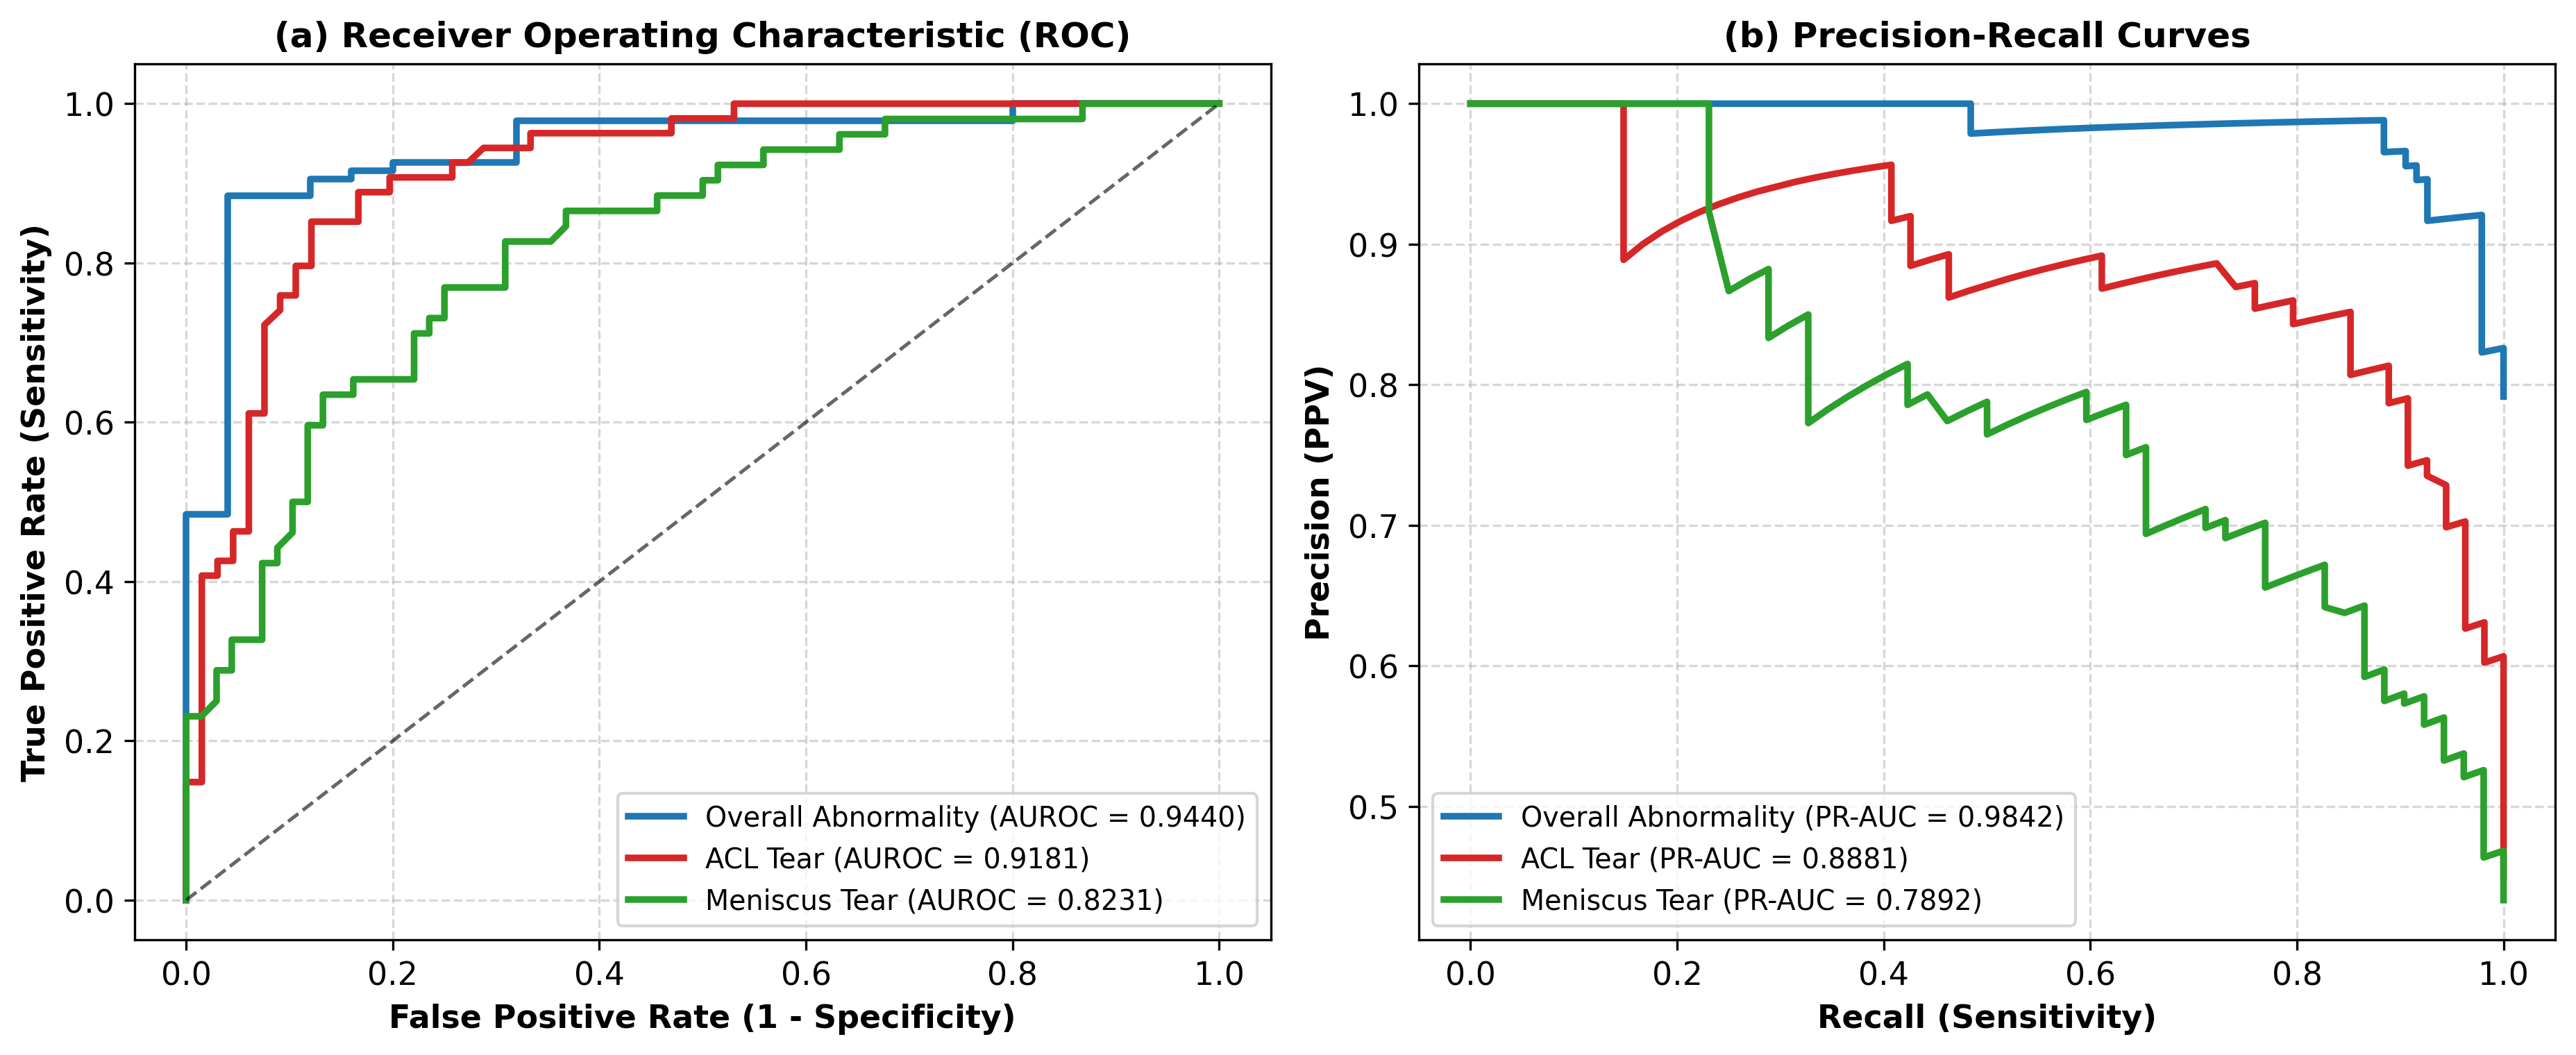

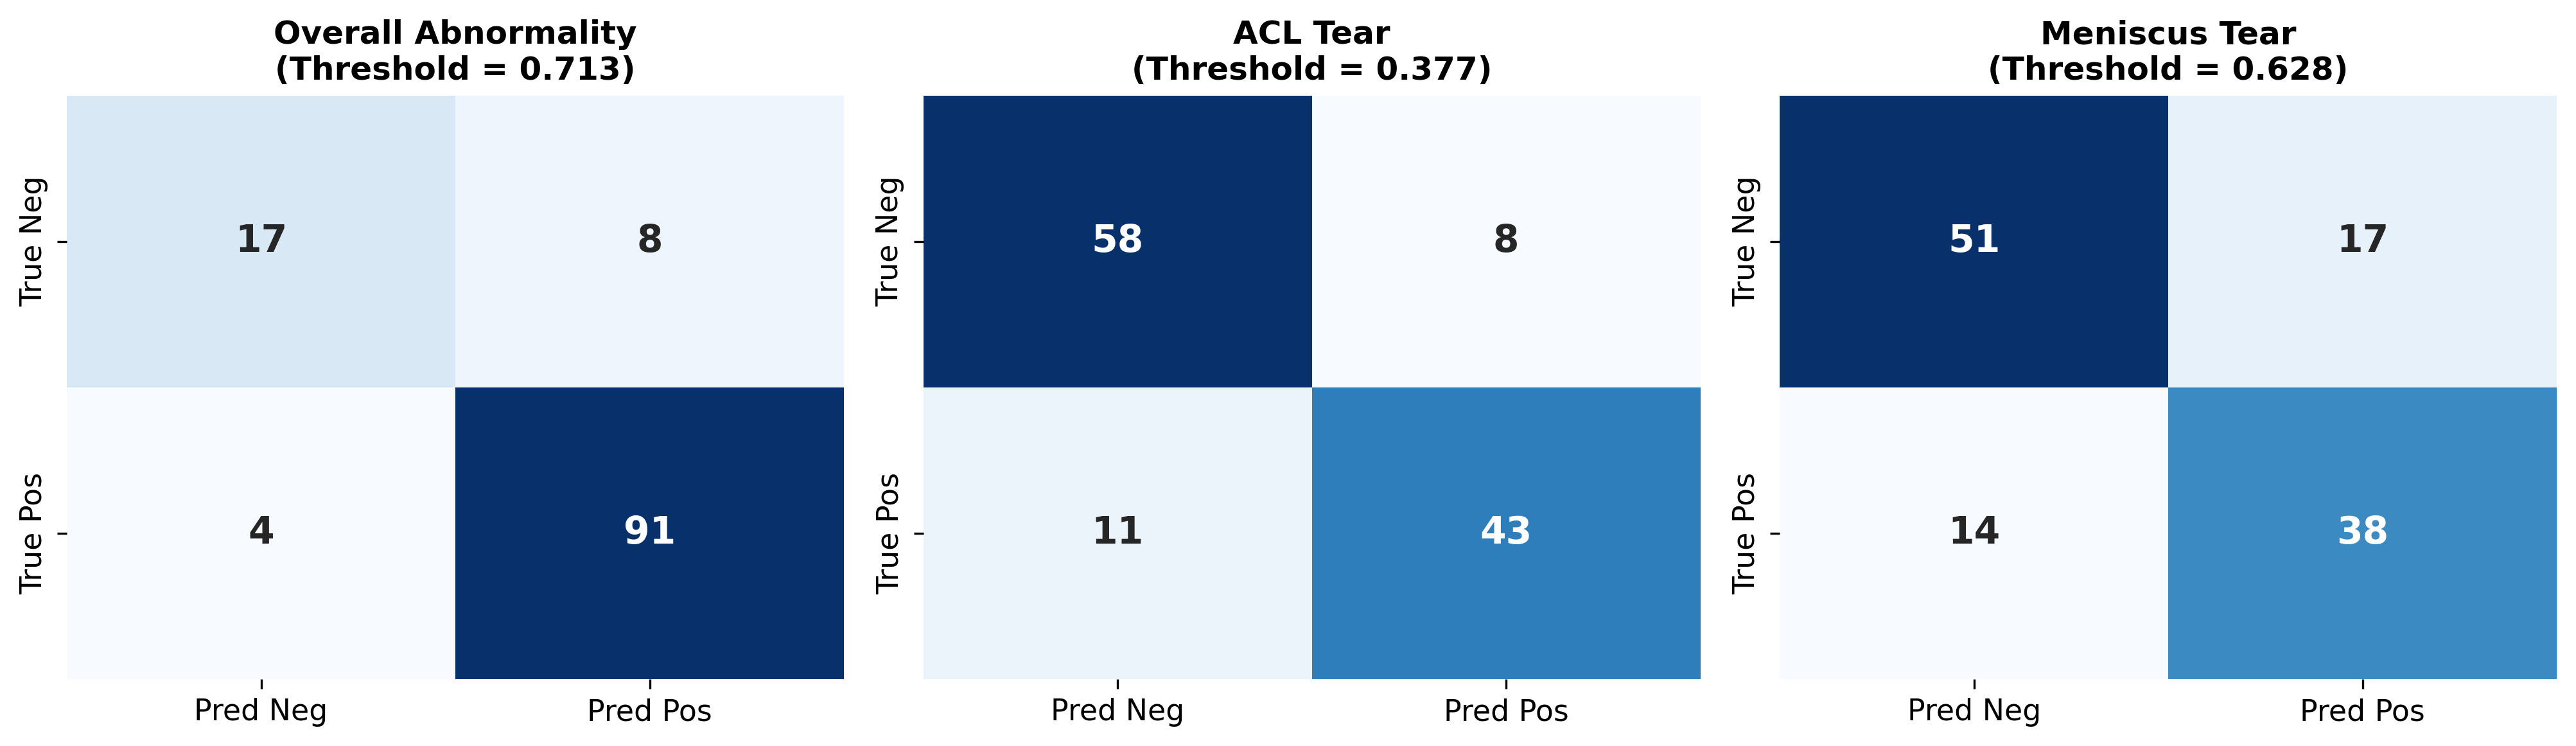

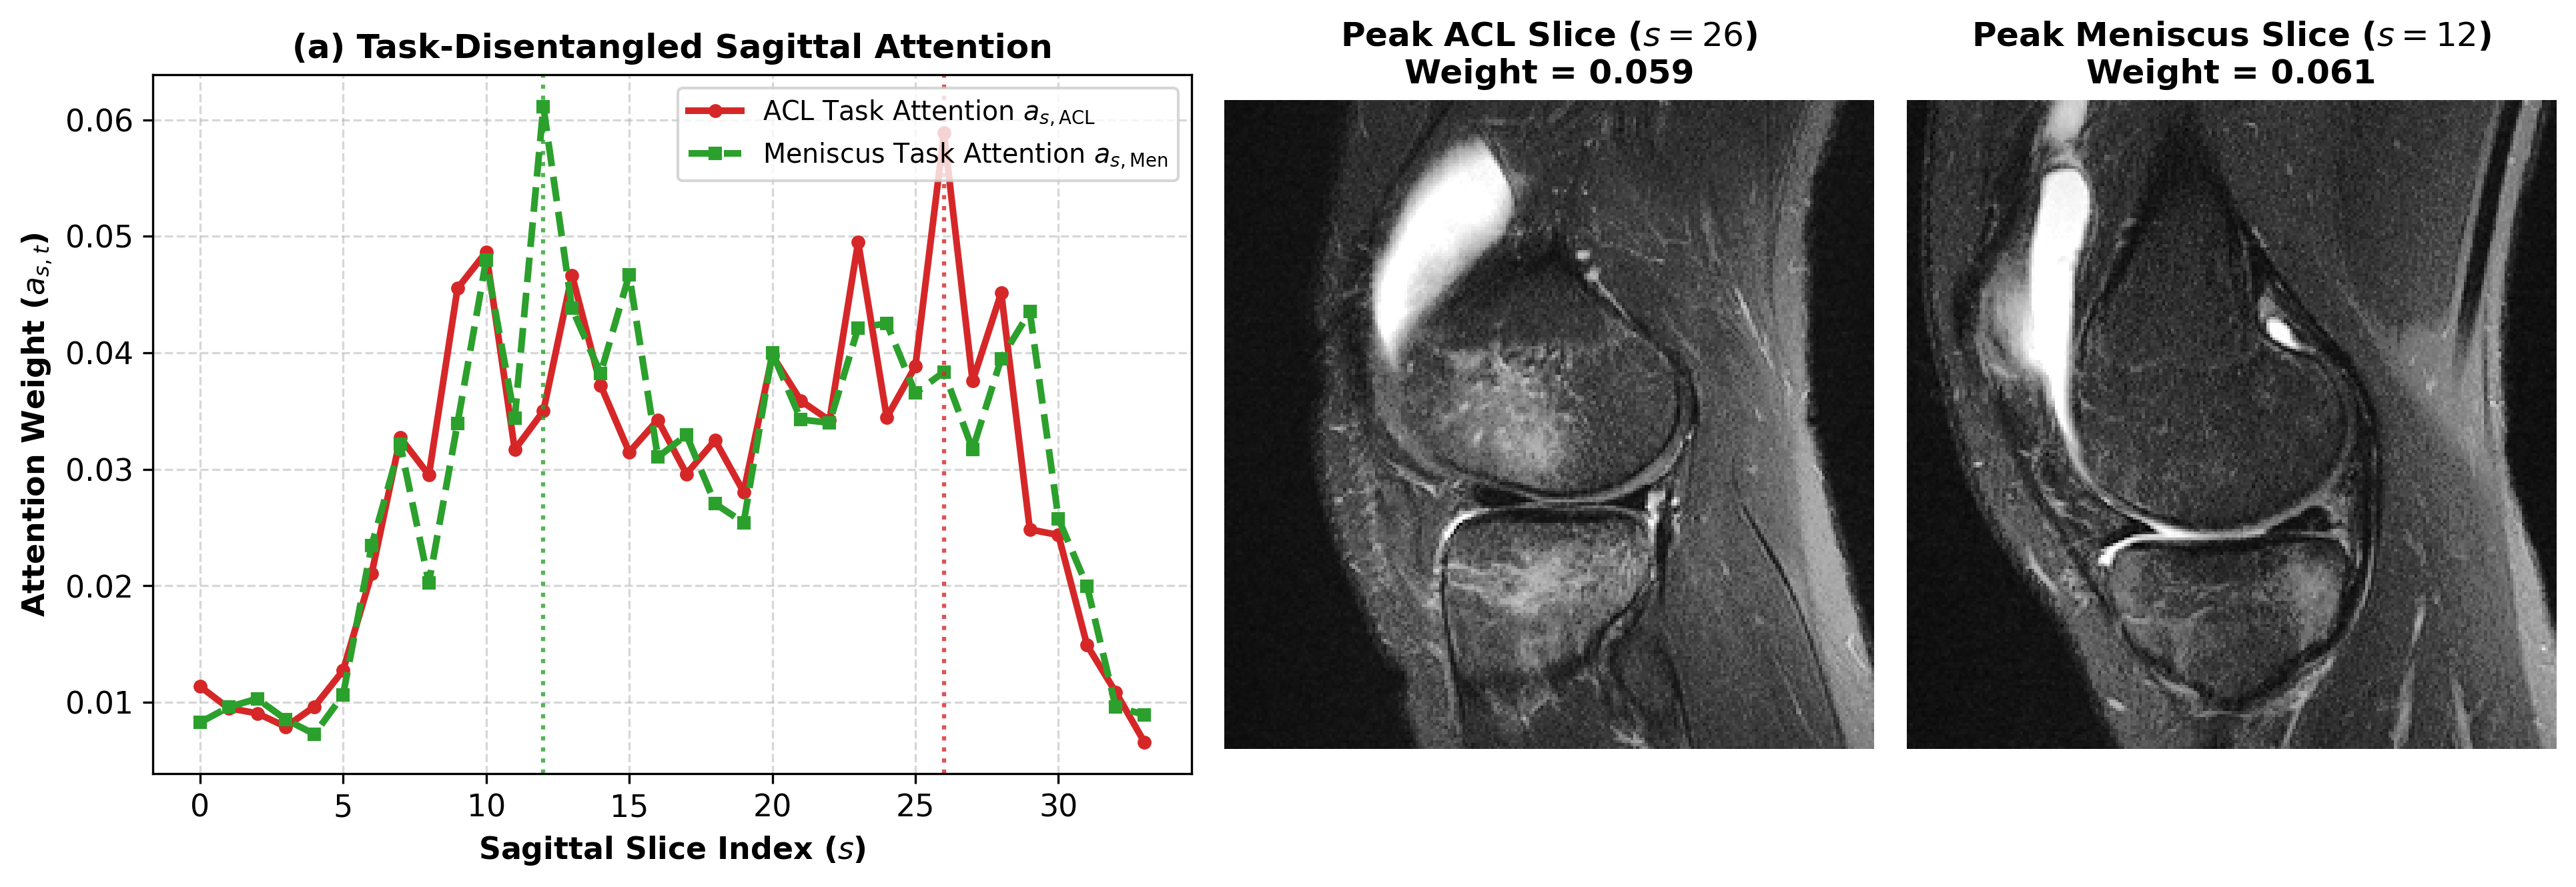

[DONE] Download fig_roc_pr.png, fig_confusion_matrices.png, and fig_attention_case.png from /kaggle/working/


In [4]:
import os
import contextlib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms.v2 as T
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve, average_precision_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. Auto-Locate Dataset & Uploaded .pth File
# ==========================================
def find_file(filename, search_roots=("/kaggle/working", "/kaggle/input")):
    for base in search_roots:
        for root, _, files in os.walk(base):
            if filename in files:
                full_path = os.path.join(root, filename)
                print(f"[INFO] Found {filename} at: {full_path}")
                return full_path
    raise FileNotFoundError(
        f"Could not find '{filename}' in /kaggle/working or /kaggle/input. "
        "Upload your downloaded .pth file via '+ Add Input -> Upload' first."
    )

def build_dataframes(root_dir):
    tasks = ["abnormal", "acl", "meniscus"]
    def load_split(prefix):
        dfs = []
        for t in tasks:
            path = os.path.join(root_dir, f"{prefix}-{t}.csv")
            df = pd.read_csv(path, header=None, names=["case", t], dtype={"case": str, t: int})
            df["case"] = df["case"].str.strip().str.zfill(4)
            dfs.append(df.set_index("case"))
        merged = pd.concat(dfs, axis=1).reset_index()
        merged["folder"] = prefix
        return merged

    full_train_df = load_split("train")
    test_df = load_split("valid")
    strat_key = (
        full_train_df["abnormal"].astype(str) + "_" +
        full_train_df["acl"].astype(str) + "_" +
        full_train_df["meniscus"].astype(str)
    )
    train_df, val_df = train_test_split(
        full_train_df, test_size=0.15, random_state=42, stratify=strat_key
    )
    return train_df, val_df, test_df

# ==========================================
# 2. V2 Dataset & Model Definitions
# ==========================================
class MRNetDatasetV2(Dataset):
    def __init__(self, root_dir, split_df, max_slices=44):
        self.root_dir = root_dir
        self.df = split_df.reset_index(drop=True)
        self.max_slices = max_slices
        self.planes = ["sagittal", "coronal", "axial"]
        self.eval_crop = T.CenterCrop(size=(224, 224))

    def __len__(self):
        return len(self.df)

    def _process_volume(self, vol):
        s = vol.shape[0]
        if s > self.max_slices:
            start = (s - self.max_slices) // 2
            vol = vol[start : start + self.max_slices]
        vol = vol.astype(np.float32) / 255.0
        vol = np.stack([vol] * 3, axis=1)
        tensor_vol = self.eval_crop(torch.from_numpy(vol))
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        return (tensor_vol - mean) / std

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        case_id = str(row["case"]).zfill(4)
        folder = row["folder"]
        volumes = {
            p: self._process_volume(np.load(os.path.join(self.root_dir, folder, p, f"{case_id}.npy")))
            for p in self.planes
        }
        labels = torch.tensor([row["abnormal"], row["acl"], row["meniscus"]], dtype=torch.float32)
        return volumes["sagittal"], volumes["coronal"], volumes["axial"], labels

class GeMPooling(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        return F.avg_pool2d(
            x.clamp(min=self.eps).pow(self.p), (x.size(-2), x.size(-1))
        ).pow(1.0 / self.p)

class TaskSpecificGatedMIL(nn.Module):
    def __init__(self, in_features, hidden_dim=256, num_tasks=3):
        super().__init__()
        self.V = nn.Linear(in_features, hidden_dim)
        self.U = nn.Linear(in_features, hidden_dim)
        self.w = nn.Linear(hidden_dim, num_tasks)
        self.dropout = nn.Dropout(0.25)

    def forward(self, h):
        scores = self.w(self.dropout(torch.tanh(self.V(h)) * torch.sigmoid(self.U(h))))
        weights = torch.softmax(scores, dim=0)
        return torch.matmul(weights.T, h), weights

class MultiPlaneDisentangledNet(nn.Module):
    def __init__(self, num_tasks=3, embed_dim=768):
        super().__init__()
        # weights=None avoids needing Internet enabled just to load local .pth weights
        backbone = models.convnext_tiny(weights=None)
        self.feature_extractor = backbone.features
        self.gem_pool = GeMPooling(p=3.0)
        self.norm_sag = nn.LayerNorm(embed_dim)
        self.norm_cor = nn.LayerNorm(embed_dim)
        self.norm_axi = nn.LayerNorm(embed_dim)
        self.mil_sag = TaskSpecificGatedMIL(embed_dim, num_tasks=num_tasks)
        self.mil_cor = TaskSpecificGatedMIL(embed_dim, num_tasks=num_tasks)
        self.mil_axi = TaskSpecificGatedMIL(embed_dim, num_tasks=num_tasks)
        self.plane_pos = nn.Parameter(torch.randn(1, 3, embed_dim) * 0.02)
        self.cross_attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=8, dropout=0.25, batch_first=True)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 2),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(embed_dim * 2, embed_dim),
        )
        self.task_heads = nn.ModuleList([
            nn.Sequential(nn.Dropout(0.3), nn.Linear(embed_dim * 3, 1)) for _ in range(num_tasks)
        ])

    def _encode_slices(self, x, plane_norm):
        return plane_norm(self.gem_pool(self.feature_extractor(x.squeeze(0))).flatten(1))

    def forward(self, sag, cor, axi):
        h_sag = self._encode_slices(sag, self.norm_sag)
        h_cor = self._encode_slices(cor, self.norm_cor)
        h_axi = self._encode_slices(axi, self.norm_axi)
        e_sag, w_sag = self.mil_sag(h_sag)
        e_cor, w_cor = self.mil_cor(h_cor)
        e_axi, w_axi = self.mil_axi(h_axi)
        tokens = torch.stack([e_sag, e_cor, e_axi], dim=1) + self.plane_pos
        attn_out, _ = self.cross_attn(tokens, tokens, tokens)
        tokens = self.norm1(tokens + attn_out)
        tokens = self.norm2(tokens + self.ffn(tokens))
        logits = torch.cat([self.task_heads[i](tokens[i].flatten().unsqueeze(0)) for i in range(3)], dim=1)
        return logits, (w_sag, w_cor, w_axi)

# ==========================================
# 3. Load Checkpoint & Generate 300 DPI Plots
# ==========================================
plt.rcParams.update({
    'font.size': 11, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.labelsize': 11, 'axes.labelweight': 'bold', 'legend.fontsize': 9.5, 'figure.dpi': 300
})

use_cuda = torch.cuda.is_available()
device = torch.device("cuda" if use_cuda else "cpu")

csv_path = find_file("train-abnormal.csv", search_roots=("/kaggle/input",))
root_dir = os.path.dirname(csv_path)
ckpt_path = find_file("best_multiplane_v2.pth")

_, val_df, test_df = build_dataframes(root_dir)
val_loader = DataLoader(MRNetDatasetV2(root_dir, val_df), batch_size=1, shuffle=False, num_workers=2)
test_loader = DataLoader(MRNetDatasetV2(root_dir, test_df), batch_size=1, shuffle=False, num_workers=2)

model = MultiPlaneDisentangledNet().to(device)
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()
print("[INFO] Successfully loaded V2 checkpoint weights!")

def collect_outputs(loader):
    targets, probs, attn_list, raw_sags = [], [], [], []
    amp_ctx = torch.amp.autocast("cuda") if use_cuda else contextlib.nullcontext()
    with torch.no_grad():
        for sag, cor, axi, labels in loader:
            with amp_ctx:
                logits, (w_sag, w_cor, w_axi) = model(sag.to(device), cor.to(device), axi.to(device))
                p = torch.sigmoid(logits).cpu().numpy()[0]
            probs.append(p)
            targets.append(labels.numpy()[0])
            attn_list.append((w_sag.cpu().numpy(), w_cor.cpu().numpy(), w_axi.cpu().numpy()))
            raw_sags.append(sag[0, :, 0].numpy())
    return np.array(targets), np.array(probs), attn_list, raw_sags

val_y, val_p, _, _ = collect_outputs(val_loader)
test_y, test_p, test_attns, test_sags = collect_outputs(test_loader)

tasks = ["Overall Abnormality", "ACL Tear", "Meniscus Tear"]
colors = ["#1f77b4", "#d62728", "#2ca02c"]

# Figure A: ROC & PR Curves
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.2))
for i, (task, col) in enumerate(zip(tasks, colors)):
    fpr, tpr, _ = roc_curve(test_y[:, i], test_p[:, i])
    axes[0].plot(fpr, tpr, color=col, lw=2.3, label=f"{task} (AUROC = {roc_auc_score(test_y[:, i], test_p[:, i]):.4f})")
    prec, rec, _ = precision_recall_curve(test_y[:, i], test_p[:, i])
    axes[1].plot(rec, prec, color=col, lw=2.3, label=f"{task} (PR-AUC = {average_precision_score(test_y[:, i], test_p[:, i]):.4f})")

axes[0].plot([0, 1], [0, 1], "k--", lw=1.2, alpha=0.6)
axes[0].set_xlabel("False Positive Rate (1 - Specificity)")
axes[0].set_ylabel("True Positive Rate (Sensitivity)")
axes[0].set_title("(a) Receiver Operating Characteristic (ROC)")
axes[0].legend(loc="lower right", frameon=True)
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].set_xlabel("Recall (Sensitivity)")
axes[1].set_ylabel("Precision (PPV)")
axes[1].set_title("(b) Precision-Recall Curves")
axes[1].legend(loc="lower left", frameon=True)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("/kaggle/working/fig_roc_pr.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure B: Confusion Matrices
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
for i, task in enumerate(tasks):
    fpr, tpr, thresh = roc_curve(val_y[:, i], val_p[:, i])
    opt_t = thresh[np.argmax(tpr - fpr)]
    cm = confusion_matrix(test_y[:, i], (test_p[:, i] >= opt_t).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[i],
                annot_kws={"size": 14, "weight": "bold"},
                xticklabels=["Pred Neg", "Pred Pos"], yticklabels=["True Neg", "True Pos"])
    axes[i].set_title(f"{task}\n(Threshold = {opt_t:.3f})")

plt.tight_layout()
plt.savefig("/kaggle/working/fig_confusion_matrices.png", dpi=300, bbox_inches="tight")
plt.show()

# Figure C: Disentangled Slice Attention + MRI Cross-Sections
case_idx = next((idx for idx in range(len(test_y)) if test_y[idx, 1] == 1 and test_y[idx, 2] == 1 and test_p[idx, 1] > 0.5 and test_p[idx, 2] > 0.5), 0)
w_sag, _, _ = test_attns[case_idx]
sag_vol = test_sags[case_idx]
acl_peak, men_peak = int(np.argmax(w_sag[:, 1])), int(np.argmax(w_sag[:, 2]))

fig = plt.figure(figsize=(13, 4.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1.6, 1, 1])

ax0 = fig.add_subplot(gs[0])
ax0.plot(np.arange(len(w_sag)), w_sag[:, 1], color="#d62728", lw=2.4, marker="o", markersize=4, label="ACL Task Attention $a_{s,\\mathrm{ACL}}$")
ax0.plot(np.arange(len(w_sag)), w_sag[:, 2], color="#2ca02c", lw=2.4, marker="s", markersize=4, linestyle="--", label="Meniscus Task Attention $a_{s,\\mathrm{Men}}$")
ax0.axvline(acl_peak, color="#d62728", linestyle=":", alpha=0.8)
ax0.axvline(men_peak, color="#2ca02c", linestyle=":", alpha=0.8)
ax0.set_xlabel("Sagittal Slice Index ($s$)")
ax0.set_ylabel("Attention Weight ($a_{s,t}$)")
ax0.set_title("(a) Task-Disentangled Sagittal Attention")
ax0.legend(loc="upper right", frameon=True)
ax0.grid(True, linestyle="--", alpha=0.5)

for ax, peak, title, task_idx in [
    (fig.add_subplot(gs[1]), acl_peak, "Peak ACL Slice", 1),
    (fig.add_subplot(gs[2]), men_peak, "Peak Meniscus Slice", 2)
]:
    img = (sag_vol[peak] - sag_vol[peak].min()) / (np.ptp(sag_vol[peak]) + 1e-6)
    ax.imshow(img, cmap="gray")
    ax.set_title(f"{title} ($s={peak}$)\nWeight = {w_sag[peak, task_idx]:.3f}")
    ax.axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/fig_attention_case.png", dpi=300, bbox_inches="tight")
plt.show()
print("[DONE] Download fig_roc_pr.png, fig_confusion_matrices.png, and fig_attention_case.png from /kaggle/working/")

[INFO] Found train-abnormal.csv at: /kaggle/input/datasets/cjinny/mrnet-v1/MRNet-v1.0/train-abnormal.csv
[INFO] Found best_multiplane_v2.pth at: /kaggle/input/datasets/armaansinha/best-multiplane-v2/best_multiplane_v2.pth
[INFO] Model, root_dir, test_df, and test_loader successfully initialized!


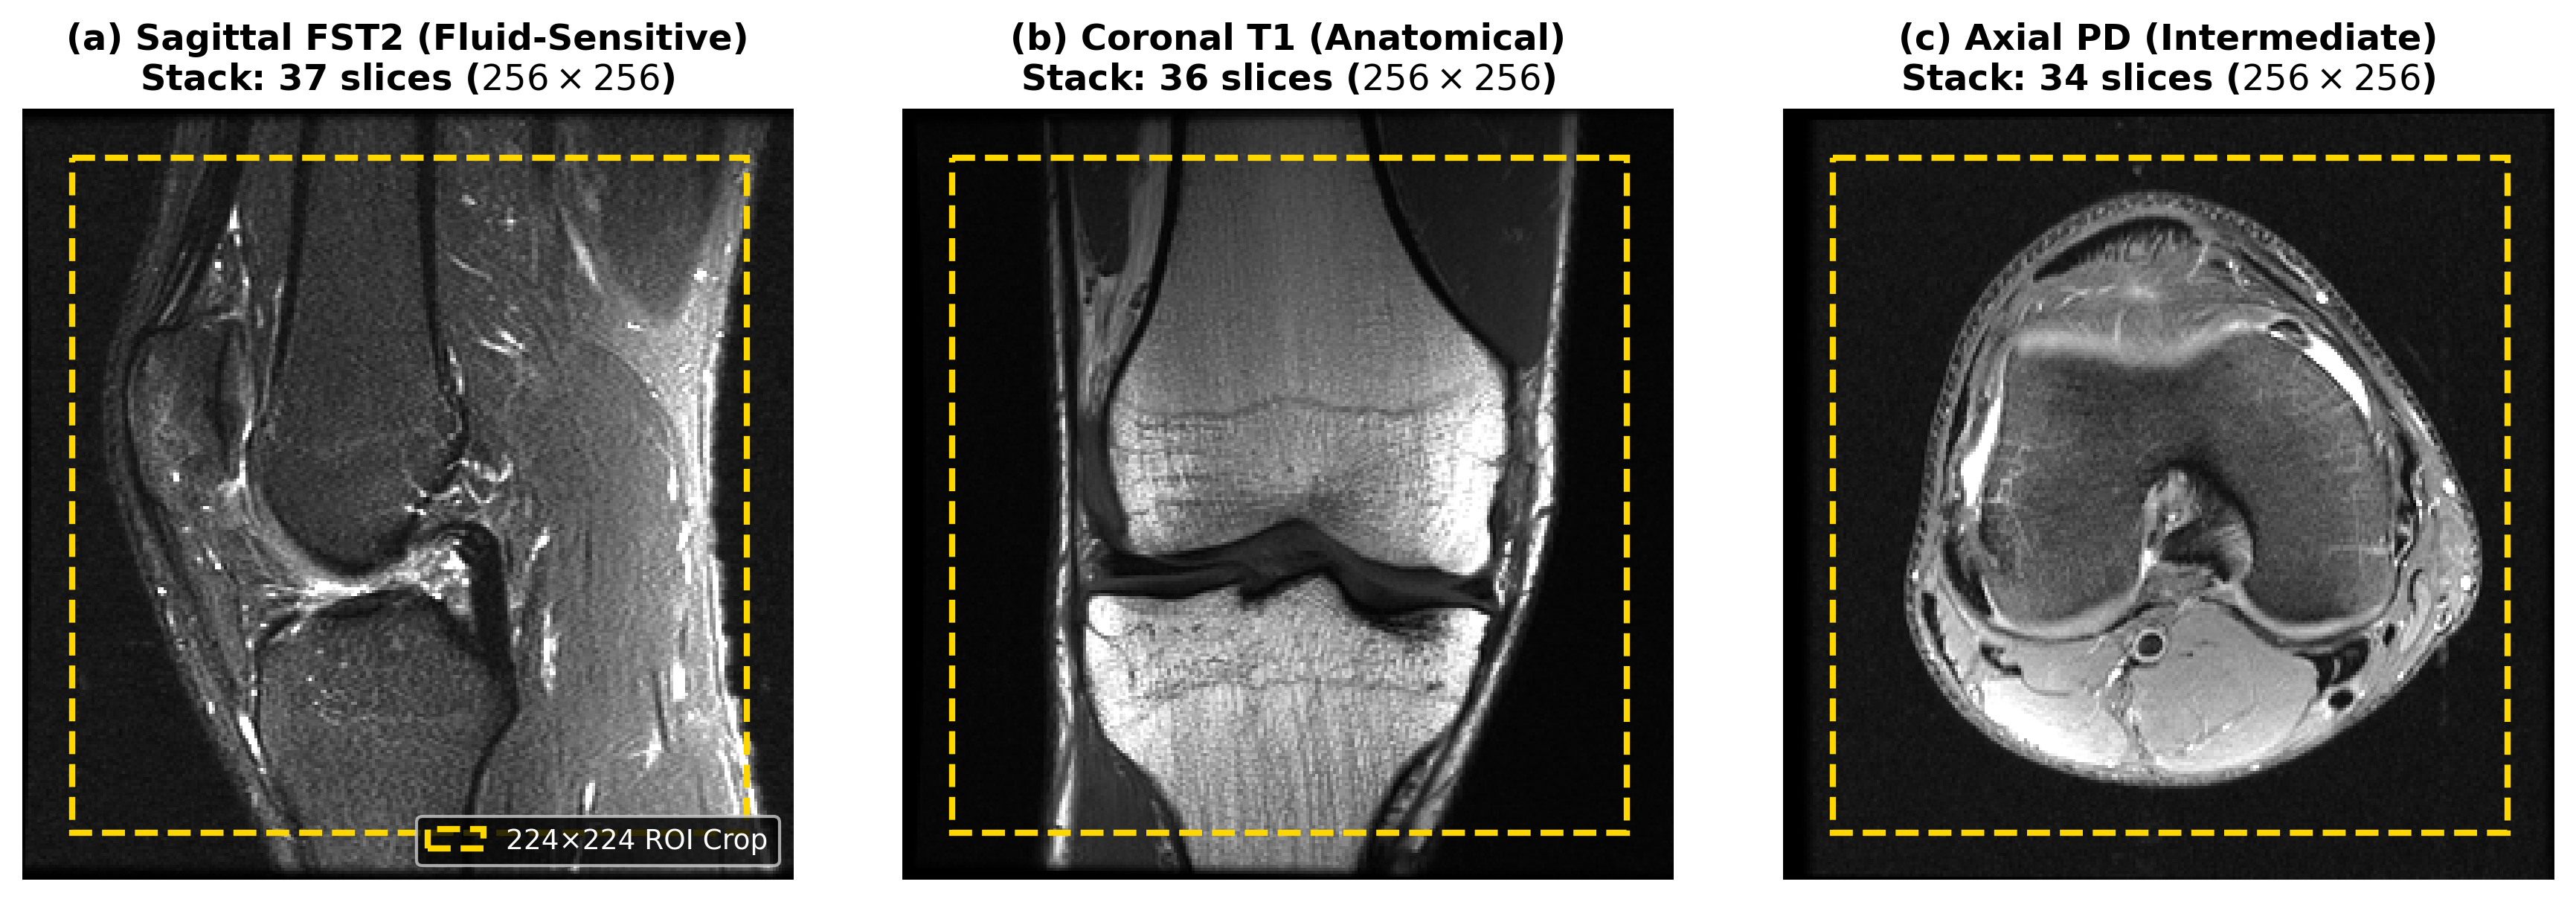

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:335.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


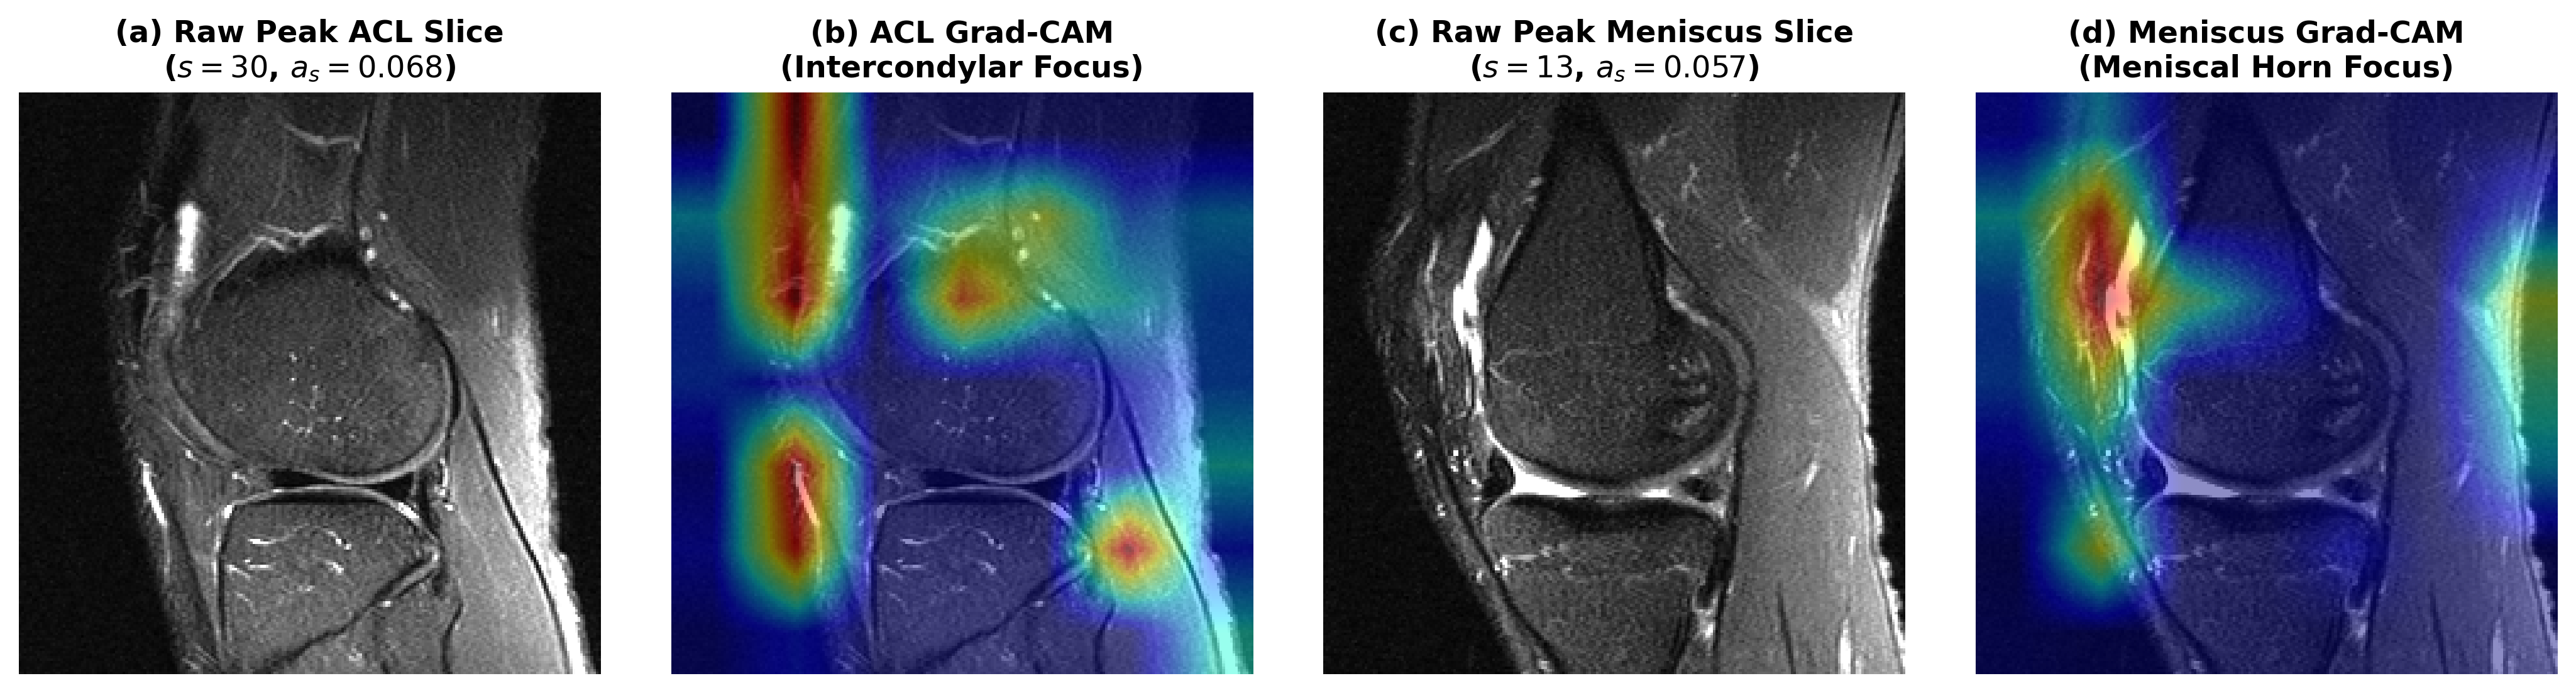

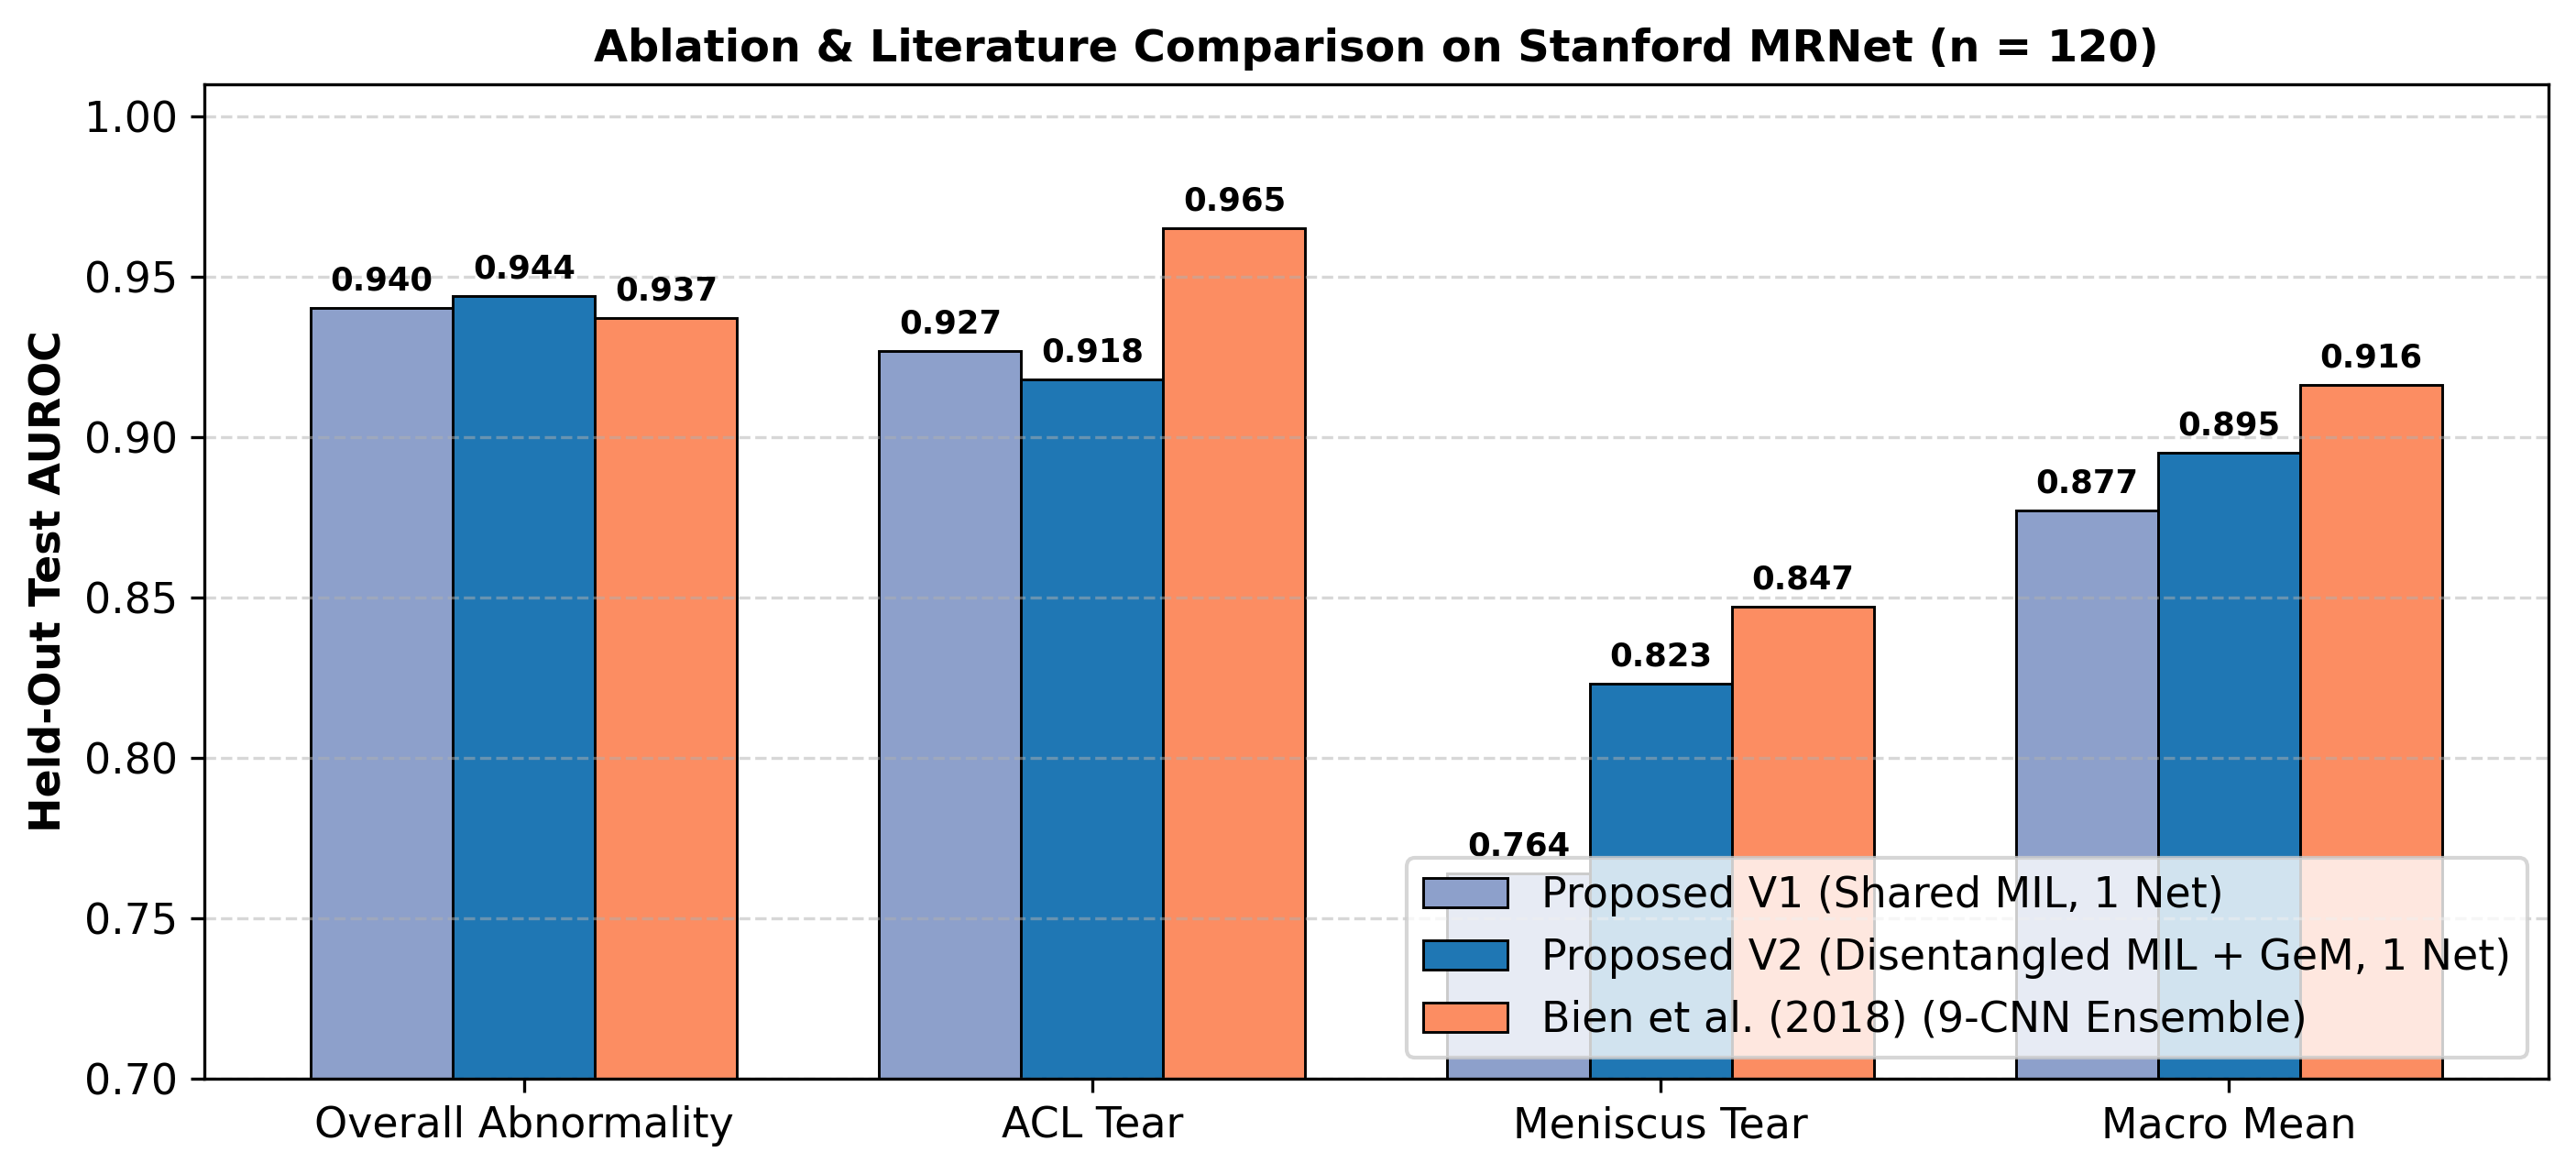

[SUCCESS] Exported all 3 figures to /kaggle/working/


In [2]:
import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models
import torchvision.transforms.v2 as T
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import matplotlib.patches as patches

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 11.5,
    'axes.titleweight': 'bold',
    'axes.labelsize': 11,
    'axes.labelweight': 'bold',
    'figure.dpi': 300
})

# ==============================================================================
# 1. Auto-Locate Files & Build DataFrames
# ==============================================================================
def find_file(filename, search_roots=("/kaggle/working", "/kaggle/input")):
    for base in search_roots:
        for root, _, files in os.walk(base):
            if filename in files:
                full_path = os.path.join(root, filename)
                print(f"[INFO] Found {filename} at: {full_path}")
                return full_path
    raise FileNotFoundError(
        f"Could not find '{filename}' in /kaggle/working or /kaggle/input. "
        "Make sure 'cjinny/mrnet-v1' is attached and 'best_multiplane_v2.pth' is uploaded."
    )

def build_dataframes(root_dir):
    tasks = ["abnormal", "acl", "meniscus"]
    def load_split(prefix):
        dfs = []
        for t in tasks:
            path = os.path.join(root_dir, f"{prefix}-{t}.csv")
            df = pd.read_csv(path, header=None, names=["case", t], dtype={"case": str, t: int})
            df["case"] = df["case"].str.strip().str.zfill(4)
            dfs.append(df.set_index("case"))
        merged = pd.concat(dfs, axis=1).reset_index()
        merged["folder"] = prefix
        return merged

    full_train_df = load_split("train")
    test_df = load_split("valid")
    strat_key = (
        full_train_df["abnormal"].astype(str) + "_" +
        full_train_df["acl"].astype(str) + "_" +
        full_train_df["meniscus"].astype(str)
    )
    train_df, val_df = train_test_split(
        full_train_df, test_size=0.15, random_state=42, stratify=strat_key
    )
    return train_df, val_df, test_df

# ==============================================================================
# 2. V2 Dataset & Architecture Definitions
# ==============================================================================
class MRNetDatasetV2(Dataset):
    def __init__(self, root_dir, split_df, max_slices=44):
        self.root_dir = root_dir
        self.df = split_df.reset_index(drop=True)
        self.max_slices = max_slices
        self.planes = ["sagittal", "coronal", "axial"]
        self.eval_crop = T.CenterCrop(size=(224, 224))

    def __len__(self):
        return len(self.df)

    def _process_volume(self, vol):
        s = vol.shape[0]
        if s > self.max_slices:
            start = (s - self.max_slices) // 2
            vol = vol[start : start + self.max_slices]
        vol = vol.astype(np.float32) / 255.0
        vol = np.stack([vol] * 3, axis=1)
        tensor_vol = self.eval_crop(torch.from_numpy(vol))
        mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
        return (tensor_vol - mean) / std

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        case_id = str(row["case"]).zfill(4)
        folder = row["folder"]
        volumes = {
            p: self._process_volume(np.load(os.path.join(self.root_dir, folder, p, f"{case_id}.npy")))
            for p in self.planes
        }
        labels = torch.tensor([row["abnormal"], row["acl"], row["meniscus"]], dtype=torch.float32)
        return volumes["sagittal"], volumes["coronal"], volumes["axial"], labels

class GeMPooling(nn.Module):
    def __init__(self, p=3.0, eps=1e-6):
        super().__init__()
        self.p = nn.Parameter(torch.ones(1) * p)
        self.eps = eps

    def forward(self, x):
        return F.avg_pool2d(
            x.clamp(min=self.eps).pow(self.p), (x.size(-2), x.size(-1))
        ).pow(1.0 / self.p)

class TaskSpecificGatedMIL(nn.Module):
    def __init__(self, in_features, hidden_dim=256, num_tasks=3):
        super().__init__()
        self.V = nn.Linear(in_features, hidden_dim)
        self.U = nn.Linear(in_features, hidden_dim)
        self.w = nn.Linear(hidden_dim, num_tasks)
        self.dropout = nn.Dropout(0.25)

    def forward(self, h):
        scores = self.w(self.dropout(torch.tanh(self.V(h)) * torch.sigmoid(self.U(h))))
        weights = torch.softmax(scores, dim=0)
        return torch.matmul(weights.T, h), weights

class MultiPlaneDisentangledNet(nn.Module):
    def __init__(self, num_tasks=3, embed_dim=768):
        super().__init__()
        backbone = models.convnext_tiny(weights=None)
        self.feature_extractor = backbone.features
        self.gem_pool = GeMPooling(p=3.0)
        self.norm_sag = nn.LayerNorm(embed_dim)
        self.norm_cor = nn.LayerNorm(embed_dim)
        self.norm_axi = nn.LayerNorm(embed_dim)
        self.mil_sag = TaskSpecificGatedMIL(embed_dim, num_tasks=num_tasks)
        self.mil_cor = TaskSpecificGatedMIL(embed_dim, num_tasks=num_tasks)
        self.mil_axi = TaskSpecificGatedMIL(embed_dim, num_tasks=num_tasks)
        self.plane_pos = nn.Parameter(torch.randn(1, 3, embed_dim) * 0.02)
        self.cross_attn = nn.MultiheadAttention(embed_dim=embed_dim, num_heads=8, dropout=0.25, batch_first=True)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.ffn = nn.Sequential(
            nn.Linear(embed_dim, embed_dim * 2),
            nn.GELU(),
            nn.Dropout(0.25),
            nn.Linear(embed_dim * 2, embed_dim),
        )
        self.task_heads = nn.ModuleList([
            nn.Sequential(nn.Dropout(0.3), nn.Linear(embed_dim * 3, 1)) for _ in range(num_tasks)
        ])

    def _encode_slices(self, x, plane_norm):
        return plane_norm(self.gem_pool(self.feature_extractor(x.squeeze(0))).flatten(1))

    def forward(self, sag, cor, axi):
        h_sag = self._encode_slices(sag, self.norm_sag)
        h_cor = self._encode_slices(cor, self.norm_cor)
        h_axi = self._encode_slices(axi, self.norm_axi)
        e_sag, w_sag = self.mil_sag(h_sag)
        e_cor, w_cor = self.mil_cor(h_cor)
        e_axi, w_axi = self.mil_axi(h_axi)
        tokens = torch.stack([e_sag, e_cor, e_axi], dim=1) + self.plane_pos
        attn_out, _ = self.cross_attn(tokens, tokens, tokens)
        tokens = self.norm1(tokens + attn_out)
        tokens = self.norm2(tokens + self.ffn(tokens))
        logits = torch.cat([self.task_heads[i](tokens[i].flatten().unsqueeze(0)) for i in range(3)], dim=1)
        return logits, (w_sag, w_cor, w_axi)

# ==============================================================================
# 3. Initialize Model, DataFrames & Loader
# ==============================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
csv_path = find_file("train-abnormal.csv", search_roots=("/kaggle/input",))
root_dir = os.path.dirname(csv_path)
ckpt_path = find_file("best_multiplane_v2.pth")

_, _, test_df = build_dataframes(root_dir)
test_loader = DataLoader(MRNetDatasetV2(root_dir, test_df), batch_size=1, shuffle=False, num_workers=2)

model = MultiPlaneDisentangledNet().to(device)
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()
print("[INFO] Model, root_dir, test_df, and test_loader successfully initialized!")

# ==============================================================================
# 4. FIGURE 1: Multi-Plane MRI Input & 224x224 ROI Crop
# ==============================================================================
sample_row = test_df[(test_df["acl"] == 1) & (test_df["meniscus"] == 1)].iloc[0]
case_id = str(sample_row["case"]).zfill(4)
folder = sample_row["folder"]

fig, axes = plt.subplots(1, 3, figsize=(12.0, 4.0))
plane_titles = [
    ("sagittal", "(a) Sagittal FST2 (Fluid-Sensitive)"),
    ("coronal", "(b) Coronal T1 (Anatomical)"),
    ("axial", "(c) Axial PD (Intermediate)")
]

for ax, (plane, title) in zip(axes, plane_titles):
    vol = np.load(os.path.join(root_dir, folder, plane, f"{case_id}.npy"))
    mid_slice = vol[len(vol) // 2]
    ax.imshow(mid_slice, cmap="gray")
    rect = patches.Rectangle((16, 16), 224, 224, linewidth=2.0, edgecolor="#FFD700",
                             facecolor="none", linestyle="--", label="224×224 ROI Crop")
    ax.add_patch(rect)
    ax.set_title(f"{title}\nStack: {vol.shape[0]} slices ($256\\times 256$)")
    ax.axis("off")

axes[0].legend(loc="lower right", frameon=True, facecolor="black", labelcolor="white", fontsize=9)
plt.tight_layout()
plt.savefig("/kaggle/working/fig_multiplane_sample.png", dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# 5. FIGURE 2: ConvNeXt-Tiny Grad-CAM Spatial Heatmaps
# ==============================================================================
def compute_sagittal_gradcam(model, sag, cor, axi, task_idx, device):
    model.eval()
    model.zero_grad()

    sag_d, cor_d, axi_d = sag.to(device), cor.to(device), axi.to(device)
    with torch.enable_grad():
        f_sag = model.feature_extractor(sag_d.squeeze(0))
        f_sag.retain_grad()
        h_sag = model.norm_sag(model.gem_pool(f_sag).flatten(1))

        with torch.no_grad():
            h_cor = model._encode_slices(cor_d, model.norm_cor)
            h_axi = model._encode_slices(axi_d, model.norm_axi)

        e_sag, w_sag = model.mil_sag(h_sag)
        e_cor, _ = model.mil_cor(h_cor)
        e_axi, _ = model.mil_axi(h_axi)

        tokens = torch.stack([e_sag, e_cor, e_axi], dim=1) + model.plane_pos
        attn_out, _ = model.cross_attn(tokens, tokens, tokens)
        tokens = model.norm1(tokens + attn_out)
        tokens = model.norm2(tokens + model.ffn(tokens))

        logit = model.task_heads[task_idx](tokens[task_idx].flatten().unsqueeze(0))
        logit.backward()

    weights_np = w_sag[:, task_idx].detach().cpu().numpy()
    peak_s = int(np.argmax(weights_np))

    act = f_sag[peak_s].detach()
    grad = f_sag.grad[peak_s].detach()
    alpha = grad.mean(dim=(1, 2), keepdim=True)
    cam = F.relu((alpha * act).sum(dim=0, keepdim=True).unsqueeze(0))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False).squeeze().cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-6)

    raw_img = sag[0, peak_s, 0].numpy()
    raw_img = (raw_img - raw_img.min()) / (np.ptp(raw_img) + 1e-6)
    return raw_img, cam, peak_s, weights_np[peak_s]

for sag, cor, axi, labels in test_loader:
    if labels[0, 1] == 1 and labels[0, 2] == 1:
        raw_acl, cam_acl, s_acl, w_acl = compute_sagittal_gradcam(model, sag, cor, axi, task_idx=1, device=device)
        raw_men, cam_men, s_men, w_men = compute_sagittal_gradcam(model, sag, cor, axi, task_idx=2, device=device)
        break

fig, axes = plt.subplots(1, 4, figsize=(14.0, 3.6))
panels = [
    (raw_acl, None, f"(a) Raw Peak ACL Slice\n($s={s_acl}$, $a_{{s}}={w_acl:.3f}$)"),
    (raw_acl, cam_acl, "(b) ACL Grad-CAM\n(Intercondylar Focus)"),
    (raw_men, None, f"(c) Raw Peak Meniscus Slice\n($s={s_men}$, $a_{{s}}={w_men:.3f}$)"),
    (raw_men, cam_men, "(d) Meniscus Grad-CAM\n(Meniscal Horn Focus)")
]

for ax, (img, cam, title) in zip(axes, panels):
    ax.imshow(img, cmap="gray")
    if cam is not None:
        ax.imshow(cam, cmap="jet", alpha=0.45)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/fig_gradcam_overlay.png", dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# 6. FIGURE 3: V1 vs V2 vs Bien et al. Benchmark Bar Chart
# ==============================================================================
metrics = ["Overall Abnormality", "ACL Tear", "Meniscus Tear", "Macro Mean"]
v1_scores   = [0.9404, 0.9268, 0.7639, 0.8770]
v2_scores   = [0.9440, 0.9181, 0.8231, 0.8951]
bien_scores = [0.9370, 0.9650, 0.8470, 0.9163]

x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(9.5, 4.4))
b1 = ax.bar(x - width, v1_scores, width, label="Proposed V1 (Shared MIL, 1 Net)", color="#8da0cb", edgecolor="black", linewidth=0.7)
b2 = ax.bar(x, v2_scores, width, label="Proposed V2 (Disentangled MIL + GeM, 1 Net)", color="#1f77b4", edgecolor="black", linewidth=0.7)
b3 = ax.bar(x + width, bien_scores, width, label="Bien et al. (2018) (9-CNN Ensemble)", color="#fc8d62", edgecolor="black", linewidth=0.7)

for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.3f}", xy=(bar.get_x() + bar.get_width() / 2, h),
                    xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.5, fontweight="bold")

ax.set_ylabel("Held-Out Test AUROC")
ax.set_title("Ablation & Literature Comparison on Stanford MRNet (n = 120)")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0.70, 1.01)
ax.grid(axis="y", linestyle="--", alpha=0.5)
ax.legend(loc="lower right", frameon=True, facecolor="white")

plt.tight_layout()
plt.savefig("/kaggle/working/fig_ablation_bar.png", dpi=300, bbox_inches="tight")
plt.show()
print("[SUCCESS] Exported all 3 figures to /kaggle/working/")